In [1]:
import tensorflow

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential

from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import AvgPool2D,MaxPool2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense

I0000 00:00:1788231967.243591  159880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788231967.244038  159880 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1788231967.286610  159880 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1788231968.484793  159880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
from tensorflow.keras.models import load_model

In [3]:
base_model = load_model("cnn_cat_dog_classifier.keras")

E0000 00:00:1788231989.272626  159880 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
base_model.layers

[<Conv2D name=conv2d, built=True>,
 <MaxPooling2D name=max_pooling2d, built=True>,
 <Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>]

In [5]:
cnn_model = Sequential()

In [6]:
for layer in base_model.layers[:3]:
    print(layer, layer.trainable)

<Conv2D name=conv2d, built=True> True
<MaxPooling2D name=max_pooling2d, built=True> True
<Flatten name=flatten, built=True> True


In [7]:
for layer in base_model.layers[:3]:
    cnn_model.add(layer)

In [8]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30752)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
cnn_model.add(Dense(kernel_initializer = "random_uniform", activation = "relu", units = 1000))

In [10]:
cnn_model.add(Dense(kernel_initializer = "random_uniform", activation = "softmax", units = 10))

In [11]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30752)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

In [14]:
from tensorflow.keras.optimizers import Adam

In [15]:
adam = Adam()

In [16]:
# loss calculating strategy -- binary_crossentropy -- binary_classification
# optimizer -- adam, RMSPROP, SGD, adagrad etc... -- Hyperparameter-- strategy(Algorithm) to update the weights
 #Fomula to update the weight
# metrics -- To calculate model performance at every epoch -- type of problem

cnn_model.compile(loss = "binary_crossentropy", optimizer = adam, metrics = ["accuracy"])

In [17]:
cnn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 31, 31, 32)       0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 30752)             0         
                                                                 
 dense (Dense)               (None, 1000)              30753000  
                                                                 
 dense_1 (Dense)             (None, 10)                10010     
                                                                 
Total params: 30,763,906
Trainable params: 30,763,906
Non-trainable params: 0
____________________________________________

In [18]:
from tensorflow.keras.utils import plot_model

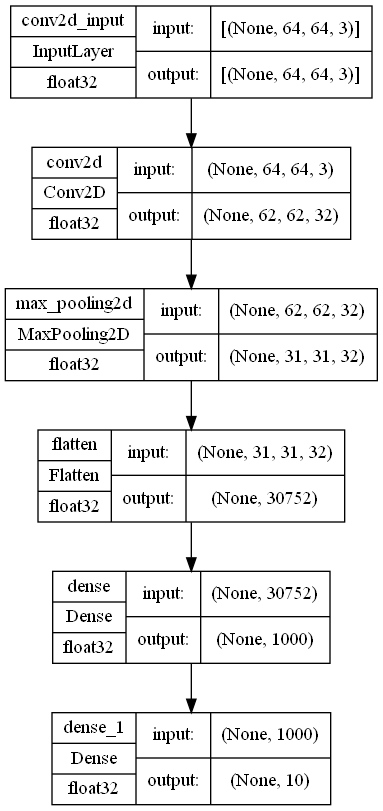

In [19]:
plot_model(cnn_model, show_shapes = True, show_dtype=True)

In [20]:
input_size = 64

### Loading the images

In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [22]:
train_gen = ImageDataGenerator(rotation_range = np.random.randint(70,100),
                   shear_range = np.random.randint(10,20),
                   zoom_range = [1.0,1.7],
                   horizontal_flip = True,
                   vertical_flip = True,
                   rescale = 1.0/255.0)

In [23]:
test_gen = ImageDataGenerator(rescale = 1.0/255.0)

In [24]:
#Train data path
#target_size -- the target size to risize each image

#class_mode == binary -- Binary Classification -- if target is 2 classes
#categorical -- Multicategorical Classification -- if target is more than 2 classes
X_train_gen = train_gen.flow_from_directory(r"E:\dataset\cnn_dataset\training_set",target_size = (input_size, input_size),
                             color_mode='rgb', class_mode = "binary", batch_size = 32)

Found 8000 images belonging to 2 classes.


In [25]:
X_train_gen

In [26]:
X_test_gen = test_gen.flow_from_directory(r"E:\dataset\cnn_dataset\test_set",target_size = (input_size, input_size),
                             color_mode='rgb', class_mode = "binary", batch_size = 32)

Found 2000 images belonging to 2 classes.


In [27]:
X_train_gen.class_indices

{'cats': 0, 'dogs': 1}

In [28]:
8000 / 32

250.0

In [23]:
X_train_gen.class_indices

{'cats': 0, 'dogs': 1}

In [24]:
from tensorflow.keras.callbacks import ModelCheckpoint

In [25]:
model_ckpt = ModelCheckpoint("cnn_cd.h5", monitor='val_accuracy', save_best_only = True, mode = 'max') 

In [26]:
cnn_model.fit(X_train_gen, epochs = 10, validation_data = X_test_gen, callbacks = model_ckpt)

Epoch 1/10
250/250 [==============================] - 131s 520ms/step - loss: 0.5904 - accuracy: 0.6869 - val_loss: 0.5850 - val_accuracy: 0.6985
Epoch 2/10
177/250 [====================>.........] - ETA: 47s - loss: 0.5848 - accuracy: 0.6944

KeyboardInterrupt: 